# California Cities — Water Area Leaders

## Objective

The main goal of this analysis is to find the **five California cities with the largest water area**. Instead of simply sorting one column, the dataset is also checked for possible data-quality issues that could affect the final results.

The analysis includes:

- reviewing the structure of the dataset,
- checking the data types and missing values in the water-area columns,
- looking for duplicate records and unusual values,
- comparing water-area values reported in different units,
- recovering missing values when they can be calculated reliably,
- comparing the original ranking with the cleaned ranking,
- and creating a clear horizontal bar chart to present the final results.

> **Analytical approach:** Original values are kept whenever possible. If a missing value can be reconstructed from other reliable information in the dataset, the new value is stored separately so that the changes remain easy to track and reproduce.

## 1. Data Loading and First Look

The first step is to load the dataset and take a quick look at its size and the first few rows. This helps confirm that the file was loaded correctly and gives a basic idea of the variables in the dataset before making any changes.

Before cleaning, the dataset has **482 rows and 14 columns**.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_csv("california_cities.csv")
df_original = df.copy()

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (482, 14)


,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576,-117.433,875.000,"2,871.000",31765,56.027,56.009,0.018,145.107,145.062,0.046,0.030
1,1,AgouraHills,34.153,-118.762,281.000,922.000,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.370
2,2,Alameda,37.756,-122.274,NaN,33.000,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.790
3,3,Albany,37.887,-122.298,NaN,43.000,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.280
4,4,Alhambra,34.082,-118.135,150.000,492.000,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.010


## 2. Structural Audit

Before ranking the cities, it is useful to check the structure of the dataset first. This includes checking for unusual data types, duplicate rows, repeated city names, and columns that are not useful for the analysis.

The dataset does not contain any duplicate rows or repeated city names, so duplicates will not affect the final ranking.

In [15]:
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate cities:", df["city"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          482 non-null    int64  
 1   city                482 non-null    object 
 2   latd                482 non-null    float64
 3   longd               482 non-null    float64
 4   elevation_m         434 non-null    float64
 5   elevation_ft        470 non-null    float64
 6   population_total    482 non-null    int64  
 7   area_total_sq_mi    480 non-null    float64
 8   area_land_sq_mi     482 non-null    float64
 9   area_water_sq_mi    481 non-null    float64
 10  area_total_km2      477 non-null    float64
 11  area_land_km2       478 non-null    float64
 12  area_water_km2      478 non-null    float64
 13  area_water_percent  477 non-null    float64
dtypes: float64(11), int64(2), object(1)
memory usage: 52.8+ KB

Column names:
['Unnamed: 0', 'city', 'latd', '

### Removing Non-Analytical Index Columns

The `Unnamed: 0` column is just an index that was saved when the file was exported, so it does not provide useful information for the analysis. Instead of removing every column with `Unnamed` in its name, the code first checks whether this column actually follows a simple row-number sequence.

After removing this unnecessary index column, **13 useful columns** remain for the analysis.

In [16]:
index_like_cols = [
    col for col in df.columns
    if col.lower().startswith("unnamed:")
    and df[col].equals(pd.Series(range(len(df)), index=df.index))
]

if index_like_cols:
    print("Dropping index-like columns:", index_like_cols)
    df = df.drop(columns=index_like_cols)

print("Clean shape:", df.shape)

Dropping index-like columns: ['Unnamed: 0']
Clean shape: (482, 13)


## 3. Water-Area Data Quality

Since the ranking is based on the water-area columns, these values need to be checked carefully. The main things to look at are the data type, missing values, and the range of the values.

All three water-area columns are stored as numeric data (`float64`). There are only a few missing values, but they are still important:

- `area_water_sq_mi`: **1** missing value
- `area_water_km2`: **4** missing values
- `area_water_percent`: **5** missing values

Even if the number of missing values is small, they should not be ignored. One of the missing values could belong to a city that should appear near the top of the ranking.

In [17]:
water_cols = [
    "area_water_sq_mi",
    "area_water_km2",
    "area_water_percent"
]

water_quality = pd.DataFrame({
    "dtype": df[water_cols].dtypes.astype(str),
    "missing_n": df[water_cols].isna().sum(),
    "missing_pct": (df[water_cols].isna().mean() * 100).round(2),
    "min": df[water_cols].min(),
    "max": df[water_cols].max()
})

display(water_quality)

,dtype,missing_n,missing_pct,min,max
area_water_sq_mi,float64,1,0.210,0.000,185.020
area_water_km2,float64,4,0.830,0.000,122.270
area_water_percent,float64,5,1.040,0.000,84.580


### Inspecting Missing Records

Before deciding how to handle the missing values, the rows with incomplete water-area information are checked one by one. This is better than removing all missing rows with `dropna()` or replacing every missing value with zero using `fillna(0)`.

The cities with missing water-area data are **FortBragg, JurupaValley, LosAltos, SanFrancisco, SantaMonica, and UnionCity**. San Francisco is particularly important because its missing water-area value in square kilometres could change the final top-five ranking.

In [18]:
missing_water_rows = df.loc[
    df[water_cols].isna().any(axis=1),
    ["city"] + water_cols
].sort_values("city")

display(missing_water_rows)

,city,area_water_sq_mi,area_water_km2,area_water_percent
143,FortBragg,NaN,0.100,NaN
197,JurupaValley,0.200,0.600,NaN
237,LosAltos,0.000,NaN,NaN
370,SanFrancisco,185.020,NaN,80.000
393,SantaMonica,0.001,NaN,NaN
443,UnionCity,0.000,NaN,NaN


## 4. Sanity Checks

Before using the water-area values in the analysis, a few basic checks are done to make sure the numbers are reasonable.

- Water area values should not be negative.
- Water percentages should be between 0 and 100.

No problems were found in these checks, which suggests that the values are reasonable based on their ranges.

In [19]:
print(
    "Negative water area (km²):",
    (df["area_water_km2"].dropna() < 0).sum()
)

print(
    "Negative water area (sq mi):",
    (df["area_water_sq_mi"].dropna() < 0).sum()
)

invalid_percent = (
    (df["area_water_percent"] < 0)
    | (df["area_water_percent"] > 100)
)

print(
    "Water percentages outside [0, 100]:",
    invalid_percent.sum()
)

Negative water area (km²): 0
Negative water area (sq mi): 0
Water percentages outside [0, 100]: 0


### Cross-Unit Consistency

Since the water area is given in both square miles and square kilometres, the two values can be compared using the standard unit conversion.

This check shows that **Fairfield** and **Fontana** may have inconsistent values. One of the two measurements for these cities could be incorrect. However, the original values are kept because the dataset does not give enough information to know which one is more reliable.

Neither Fairfield nor Fontana appears in the final top-five ranking, so these inconsistencies do not affect the final result.

In [20]:
SQMI_TO_KM2 = 2.5899

qc = df.loc[
    df["area_water_sq_mi"].notna()
    & df["area_water_km2"].notna(),
    ["city", "area_water_sq_mi", "area_water_km2"]
].copy()

qc["expected_water_km2"] = (
    qc["area_water_sq_mi"] * SQMI_TO_KM2
)

qc["abs_error"] = (
    qc["area_water_km2"] - qc["expected_water_km2"]
).abs()

qc["relative_error"] = (
    qc["abs_error"]
    / qc["expected_water_km2"].replace(0, np.nan)
)

suspicious_units = qc.loc[
    (qc["abs_error"] > 0.1)
    & (qc["relative_error"] > 0.05)
]

display(suspicious_units)

,city,area_water_sq_mi,area_water_km2,expected_water_km2,abs_error,relative_error
136,Fairfield,3.245,2.635,8.404,5.769,0.686
142,Fontana,3.000,6.000,7.770,1.770,0.228


## 5. Investigating Missing `area_water_km2`

Instead of filling in the missing km² values with a statistical method, related columns in the dataset are used to check whether the missing value can be calculated directly.

For **San Francisco**:

- total area = **231.890 sq mi**
- land area = **46.870 sq mi**
- difference = **185.020 sq mi**

This difference is exactly the same as the recorded `area_water_sq_mi` value. This gives good evidence that the water-area value in square miles is correct.

In [21]:
missing_km2 = df.loc[
    df["area_water_km2"].isna(),
    [
        "city",
        "area_total_sq_mi",
        "area_land_sq_mi",
        "area_water_sq_mi",
        "area_water_km2"
    ]
].copy()

missing_km2["water_from_total_minus_land"] = (
    missing_km2["area_total_sq_mi"]
    - missing_km2["area_land_sq_mi"]
)

display(missing_km2)

,city,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_water_km2,water_from_total_minus_land
237,LosAltos,6.487,6.487,0.000,NaN,0.000
370,SanFrancisco,231.890,46.870,185.020,NaN,185.020
393,SantaMonica,8.416,8.415,0.001,NaN,0.001
443,UnionCity,19.000,19.000,0.000,NaN,0.000


### Deterministic Reconstruction

The missing value in km² is calculated from the available square-mile value using the standard conversion between the two units. Since the result comes directly from a fixed conversion, this is a deterministic reconstruction rather than a statistical estimate.

Instead of changing the original column, a new cleaned column is created. This keeps the original data unchanged and makes it easier to see which values were reconstructed.

For San Francisco, the reconstructed water area is about **479.2 km²**.

In [22]:
df["area_water_km2_clean"] = df["area_water_km2"]

recover_mask = (
    df["area_water_km2_clean"].isna()
    & df["area_water_sq_mi"].notna()
)

df.loc[
    recover_mask,
    "area_water_km2_clean"
] = (
    df.loc[recover_mask, "area_water_sq_mi"]
    * SQMI_TO_KM2
)

df["water_km2_reconstructed"] = recover_mask

display(
    df.loc[
        recover_mask,
        [
            "city",
            "area_water_sq_mi",
            "area_water_km2",
            "area_water_km2_clean"
        ]
    ]
)

,city,area_water_sq_mi,area_water_km2,area_water_km2_clean
237,LosAltos,0.000,NaN,0.000
370,SanFrancisco,185.020,NaN,479.183
393,SantaMonica,0.001,NaN,0.003
443,UnionCity,0.000,NaN,0.000


## 6. Raw Ranking

First, the cities are ranked using the original `area_water_km2` column. This gives a useful baseline and shows what the result would look like if the missing values were not handled.

Because San Francisco has a missing value in the original `area_water_km2` column, it is left out of this ranking. This shows why checking and cleaning the data is important before deciding on the final top-five cities.

In [23]:
raw_top5 = (
    df.nlargest(5, "area_water_km2")
      [["city", "area_water_km2"]]
      .reset_index(drop=True)
)

raw_top5.index += 1

print("Top 5 using the raw area_water_km2 column:")
display(raw_top5)

Top 5 using the raw area_water_km2 column:


,city,area_water_km2
1,SanDiego,122.270
2,LosAngeles,88.000
3,NewportBeach,75.557
4,Coronado,64.062
5,DanaPoint,59.536


### Cleaned Ranking

After filling in the missing value using the reliable conversion, the ranking changes.

The final top five cities are:

1. **SanFrancisco** — about 479.2 km²  
2. **SanDiego** — 122.27 km²  
3. **LosAngeles** — 88.00 km²  
4. **NewportBeach** — 75.557 km²  
5. **Coronado** — 64.062 km²  

The main point is that San Francisco would have been missed if the rows with missing values had simply been removed with `dropna()`.

In [24]:
top5 = (
    df.nlargest(5, "area_water_km2_clean")
      [
          [
              "city",
              "area_water_km2_clean",
              "water_km2_reconstructed"
          ]
      ]
      .reset_index(drop=True)
)

top5.index += 1
top5.index.name = "rank"

display(top5)

,city,area_water_km2_clean,water_km2_reconstructed
rank,,,
1,SanFrancisco,479.183,True
2,SanDiego,122.270,False
3,LosAngeles,88.000,False
4,NewportBeach,75.557,False
5,Coronado,64.062,False


7. Visualization

A horizontal bar chart is used to present the final ranking because it makes the differences between the cities easy to compare. The cities are ordered from the largest water area to the smallest, with the highest value shown at the top.

To make the chart more informative, reconstructed values are shown with a hatched pattern, while the original values are displayed normally.

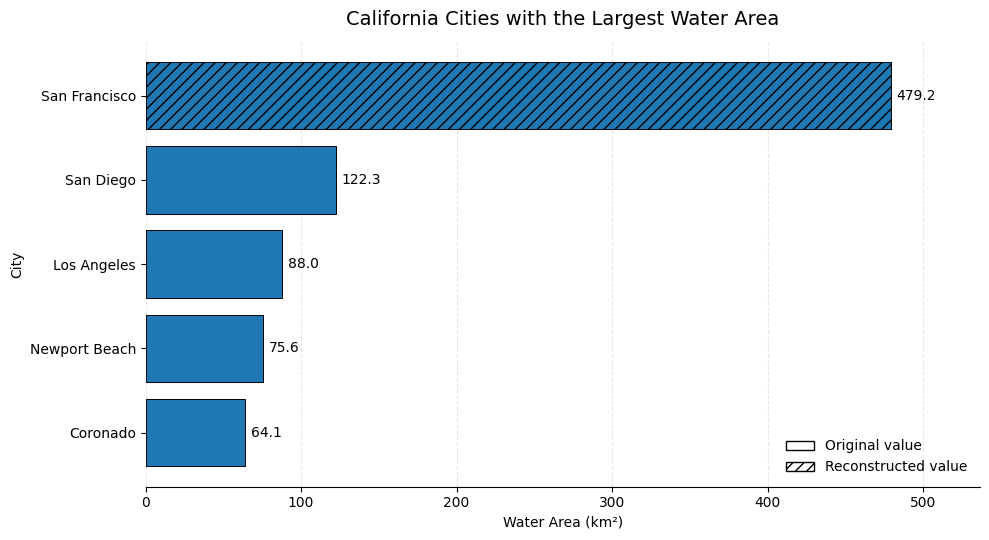

In [25]:
plot_df = top5.reset_index().copy()

city_labels = {
    "SanFrancisco": "San Francisco",
    "SanDiego": "San Diego",
    "LosAngeles": "Los Angeles",
    "NewportBeach": "Newport Beach",
    "Coronado": "Coronado"
}

plot_df["city_label"] = (
    plot_df["city"]
    .map(city_labels)
    .fillna(plot_df["city"])
)

plot_df = plot_df.sort_values(
    "area_water_km2_clean",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    plot_df["city_label"],
    plot_df["area_water_km2_clean"],
    edgecolor="black",
    linewidth=0.7
)

for bar, reconstructed in zip(
    bars,
    plot_df["water_km2_reconstructed"]
):
    if reconstructed:
        bar.set_hatch("///")

ax.invert_yaxis()

ax.set_title(
    "California Cities with the Largest Water Area",
    fontsize=14,
    pad=12
)

ax.set_xlabel("Water Area (km²)")
ax.set_ylabel("City")

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=4
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

legend_items = [
    Patch(
        facecolor="white",
        edgecolor="black",
        label="Original value"
    ),
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch="///",
        label="Reconstructed value"
    )
]

ax.legend(
    handles=legend_items,
    frameon=False,
    loc="lower right"
)

ax.margins(x=0.12)

plt.tight_layout()
plt.show()

## Conclusion

The final ranking was based not only on the water-area values, but also on checking the quality of the data. The main issue was the missing `area_water_km2` value for **San Francisco**. Since its water area in square miles is available and matches the difference between total area and land area, the missing km² value can be calculated reliably using the standard unit conversion.

After this correction, **San Francisco becomes the city with the largest water area in the dataset, with about 479.2 km²**.

The analysis also found some inconsistencies between the square-mile and square-kilometre values for Fairfield and Fontana. These values were kept unchanged because the dataset does not provide enough information to decide which one is correct. This keeps the analysis clear and makes the final ranking easier to reproduce and check.